# (b) Roofline: where each operation sits

Every op from one forward step is placed at (arithmetic intensity, attained
FLOP/s). Ceilings: tensor-core peak (matmuls), vector peak (norms, softmax,
activations), and memory bandwidth. Because these are *predicted* points,
each one lies on its own ceiling by construction. What the plot shows is
**which ceiling** each op hits, and how far it is from the ridge.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotstyle as ps
from perfmodel import load_model, load_chip, predict_step
ps.apply()
pd.set_option("display.precision", 3)

In [2]:
def op_points(r):
    rows = []
    for o in r.ops:
        b = o.sram_bytes + o.dram_bytes
        if o.flops == 0 or b == 0 or o.time == 0:
            continue  # embedding (no FLOPs) and fused softmax (no bytes) can't be placed
        rows.append({"op": o.name, "kind": o.kind, "intensity": o.flops / b,
                     "tflops": o.flops / (o.time) / 1e12, "time_share": o.time / r.time_s,
                     "bound": o.bound})
    return pd.DataFrame(rows)

def draw_ceilings(ax, chip, dtype, x, mem_levels):
    peak = chip.peak_flops(dtype) / 1e12
    vec = chip.peak_flops(chip.vector_dtype) / 1e12
    for name, bw in mem_levels:
        y = np.minimum(peak, x * bw / 1e12)
        ax.plot(x, y, color=ps.NEUTRAL, lw=1.4)
        i = np.searchsorted(x, peak * 1e12 / bw / 5)  # on the slope, left of this ridge
        ax.annotate(f"{name} {bw/1e12:.3g} TB/s", (x[i], x[i] * bw / 1e12), color=ps.INK_2,
                    fontsize=8, xytext=(-8, 6), textcoords="offset points", ha="right")
    ax.axhline(vec, color=ps.NEUTRAL, lw=1, ls=":")
    ax.annotate(f"{chip.vector_dtype} vector peak {vec:g} TFLOP/s", (x[0], vec), ha="left",
                xytext=(0, 5), textcoords="offset points", fontsize=8, color=ps.INK_2)
    ax.annotate(f"{dtype} peak {peak:g} TFLOP/s", (x[-1], peak), ha="right",
                xytext=(0, -12), textcoords="offset points", fontsize=8, color=ps.INK_2)

## Llama 3.2 1B (bf16) on A100: decode at batch 1 and 256, prefill of 2048 tokens

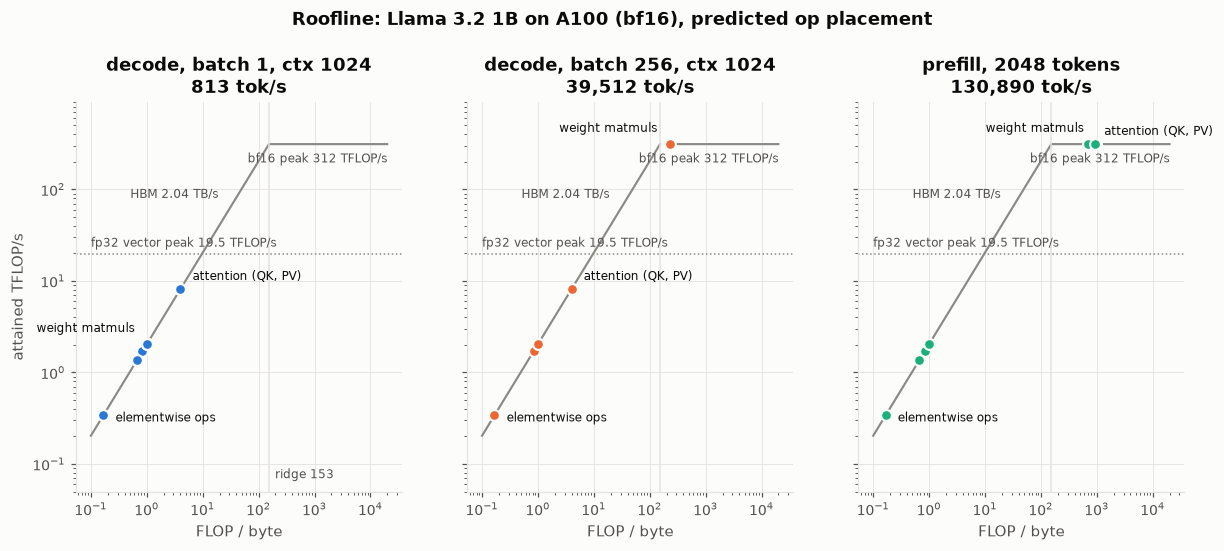

In [3]:
m, a100 = load_model("llama3.2-1b"), load_chip("a100")
scen = {
    "decode, batch 1, ctx 1024": predict_step(m, a100, 1, 1024, 1),
    "decode, batch 256, ctx 1024": predict_step(m, a100, 256, 1024, 1),
    "prefill, 2048 tokens": predict_step(m, a100, 1, 0, 2048),
}
x = np.logspace(-1, 4.3, 400)
ridge = a100.peak_flops(m.compute_dtype) / a100.dram_bw
LABEL = {"mlp_up": ("weight matmuls", -8, 8, "right"),
         "attn_scores": ("attention (QK, PV)", 8, 6, "left"),
         "residual_add": ("elementwise ops", 8, -4, "left")}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharex=True, sharey=True)
for i, (ax, (label, r)) in enumerate(zip(axes, scen.items())):
    draw_ceilings(ax, a100, m.compute_dtype, x, [("HBM", a100.dram_bw)])
    ax.axvline(ridge, color=ps.GRID, lw=1)
    p = op_points(r)
    ax.scatter(p.intensity, p.tflops, s=50, color=ps.SERIES[i], edgecolor=ps.SURFACE, lw=1.4,
               zorder=3)
    for op, (text, dx, dy, ha) in LABEL.items():
        row = p[p.op == op]
        if len(row):
            ax.annotate(text, (row.intensity.item(), row.tflops.item()), fontsize=8,
                        color=ps.INK, xytext=(dx, dy), textcoords="offset points", ha=ha)
    ax.set(xscale="log", yscale="log", title=f"{label}\n{r.tokens_per_s:,.0f} tok/s",
           xlabel="FLOP / byte", ylim=(0.05, 900))
axes[0].set_ylabel("attained TFLOP/s")
axes[0].annotate(f"ridge {ridge:.0f}", (ridge, 0.07), fontsize=8, color=ps.INK_2,
                 xytext=(4, 0), textcoords="offset points")
fig.suptitle("Roofline: Llama 3.2 1B on A100 (bf16), predicted op placement", fontsize=12,
             color=ps.INK, fontweight="bold", y=1.06)
ps.save(fig, "roofline_a100");

In [4]:
pd.concat({k: op_points(r).set_index("op")[["intensity", "tflops", "time_share", "bound"]]
           for k, r in scen.items()}, axis=1).round(3)

decode, batch 1, ctx 1024                            \
                             intensity tflops time_share   bound   
op                                                                 
attn_norm                        0.667  1.359      0.000  memory   
qkv_proj                         1.000  2.039      0.080  memory   
attn_scores                      3.984  8.124      0.007  memory   
attn_output                      3.984  8.124      0.007  memory   
o_proj                           0.999  2.037      0.054  memory   
residual_add                     0.167  0.340      0.000  memory   
mlp_norm                         0.667  1.359      0.000  memory   
mlp_up                           0.999  2.038      0.428  memory   
mlp_act                          0.833  1.699      0.000  memory   
mlp_down                         0.999  2.038      0.214  memory   
final_norm                       0.667  1.359      0.000  memory   
lm_head                          1.000  2.038      0.210  memory   

             decode, batch 256, ctx 1024                               \
                               intensity   tflops time_share    bound   
op                                                                      
attn_norm                          0.998    2.035      0.003   memory   
qkv_proj                         211.991  312.000      0.026  compute   
attn_scores                        3.984    8.124      0.327   memory   
attn_output                        3.984    8.124      0.327   memory   
o_proj                           204.800  312.000      0.017  compute   
residual_add                       0.167    0.340      0.008   memory   
mlp_norm                           0.998    2.035      0.003   memory   
mlp_up                           224.438  312.000      0.136  compute   
mlp_act                            0.833    1.699      0.015   memory   
mlp_down                         221.405  312.000      0.068  compute   
final_norm                         0.998    2.035      0.000   memory   
lm_head                          227.153  312.000      0.067  compute   

             prefill, 2048 tokens                               
                        intensity   tflops time_share    bound  
op                                                              
attn_norm                   1.000    2.039      0.008   memory  
qkv_proj                  768.469  312.000      0.085  compute  
attn_scores               819.600  312.000      0.028  compute  
attn_output               819.600  312.000      0.028  compute  
o_proj                    682.667  312.000      0.056  compute  
residual_add                0.167    0.340      0.025   memory  
mlp_norm                    1.000    2.039      0.008   memory  
mlp_up                    963.765  312.000      0.450  compute  
mlp_act                     0.833    1.699      0.050   memory  
mlp_down                  910.222  312.000      0.225  compute  
final_norm                  0.667    1.359      0.000   memory  
lm_head                     1.000    2.038      0.016   memory

**Reading it.** At batch 1, every weight matmul sits at intensity ≈ 1 FLOP/B
(2 FLOPs per 2-byte weight), about 150x left of the ridge. Attention sits at
≈ 4 FLOP/B because of GQA: the 4 query heads in each group share one K/V
read. At batch 256 the weight matmuls slide right to ≈ 200-230 FLOP/B and become
compute-bound. Attention does not move, because every sequence has its own
KV cache, so batching never amortizes it. In prefill, the matmuls are far
right of the ridge and the elementwise ops become the memory-bound tail.

## Where the time goes

The same model, five operating points. Ops are grouped by what limits them.
At batch 1 the step is almost all weight streaming. Long context or large
batch hands the step to attention (KV-cache reads). In prefill the weight
matmuls are back on top, now compute-bound.

,weight matmuls,LM head,attention (KV reads),elementwise + embedding
decode B=1 ctx 1k,0.776,0.210,0.014,0.001
decode B=1 ctx 32k,0.547,0.148,0.304,0.000
decode B=64 ctx 4k,0.179,0.048,0.765,0.008
decode B=256 ctx 1k,0.246,0.067,0.659,0.028
prefill 2k tokens,0.817,0.016,0.074,0.093


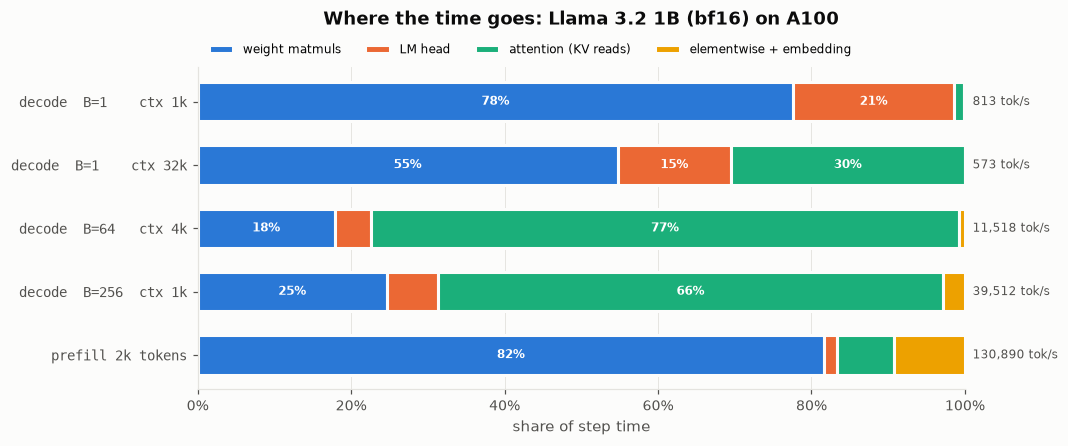

In [5]:
GROUPS = {
    "weight matmuls": ["qkv_proj", "o_proj", "mlp_up", "mlp_down"],
    "LM head": ["lm_head"],
    "attention (KV reads)": ["attn_scores", "attn_softmax", "attn_output"],
    "elementwise + embedding": ["embedding", "attn_norm", "mlp_norm", "residual_add",
                                "mlp_act", "final_norm"],
}
cases = {
    "decode  B=1    ctx 1k": predict_step(m, a100, 1, 1024, 1),
    "decode  B=1    ctx 32k": predict_step(m, a100, 1, 32768, 1),
    "decode  B=64   ctx 4k": predict_step(m, a100, 64, 4096, 1),
    "decode  B=256  ctx 1k": predict_step(m, a100, 256, 1024, 1),
    "prefill 2k tokens": predict_step(m, a100, 1, 0, 2048),
}
share = pd.DataFrame({
    case: {g: sum(o.time for o in r.ops if o.name in ops) / r.time_s for g, ops in GROUPS.items()}
    for case, r in cases.items()
}).T

fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(share))
ys = np.arange(len(share))[::-1]
for i, g in enumerate(share.columns):
    v = share[g].values
    ax.barh(ys, v, left=left, color=ps.SERIES[i], height=0.62, label=g,
            edgecolor=ps.SURFACE, linewidth=2)
    for y, x0, w in zip(ys, left, v):
        if w >= 0.1:
            ax.text(x0 + w / 2, y, f"{100 * w:.0f}%", ha="center", va="center", fontsize=8,
                    color="white", fontweight="bold")
    left += v
for y, r in zip(ys, cases.values()):
    ax.text(1.01, y, f"{r.tokens_per_s:,.0f} tok/s", va="center", fontsize=8, color=ps.INK_2)
ax.set_yticks(ys, share.index, fontfamily="monospace", fontsize=9)
ax.set(xlim=(0, 1), xlabel="share of step time")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.grid(axis="y", visible=False)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
ax.set_title("Where the time goes: Llama 3.2 1B (bf16) on A100", pad=28)
ps.save(fig, "time_breakdown");
share.round(3)

## SRAM-heavy design point: Llama 3.2 1B at 4-bit, decode batch 1, weights resident vs streamed

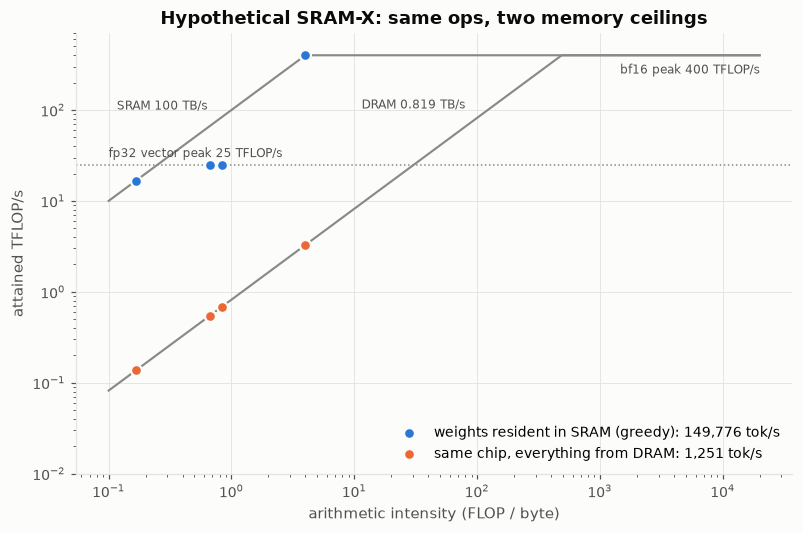

In [6]:
m4, sx = load_model("llama3.2-1b").with_(weight_bits=4), load_chip("sram-accel")
res = {"weights resident in SRAM (greedy)": predict_step(m4, sx, 1, 1024, 1),
       "same chip, everything from DRAM": predict_step(m4, sx, 1, 1024, 1, placement_policy="none")}
fig, ax = plt.subplots(figsize=(8.4, 5.2))
draw_ceilings(ax, sx, m4.compute_dtype, x, [("SRAM", sx.sram_bw), ("DRAM", sx.dram_bw)])
for i, (label, r) in enumerate(res.items()):
    p = op_points(r)
    ax.scatter(p.intensity, p.tflops, s=50, color=ps.SERIES[i], edgecolor=ps.SURFACE, lw=1.4,
               zorder=3, label=f"{label}: {r.tokens_per_s:,.0f} tok/s")
ax.set(xscale="log", yscale="log", xlabel="arithmetic intensity (FLOP / byte)",
       ylabel="attained TFLOP/s", ylim=(0.01, 700),
       title="Hypothetical SRAM-X: same ops, two memory ceilings")
ax.legend(loc="lower right")
ps.save(fig, "roofline_sram_accel");

The ops have the same intensities in both cases. (At 4-bit a weight matmul does
4 FLOP/B, and against 100 TB/s SRAM that already reaches the 400 TFLOP/s
peak: **with resident weights, batch-1 decode is compute-bound.**) Placement only changes which
ceiling they sit under. Residency moves them up the 100 TB/s SRAM line, about
120x above the 0.8 TB/s DRAM line. That gap is the whole argument for
SRAM-heavy inference silicon, and it only holds while the model fits (see
the design study).